<a href="https://colab.research.google.com/github/rajalakshmie-png/confidentiality-gate/blob/main/LAF_MCDM_full_experiments_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAF-MCDM · Full experimental results (Section V)
**Paper ID 26CYBS272 · ICSSS’26** — E. Rajalakshmi, S. Renuka Devi

Self-contained for Google Colab: use **Runtime → Run all**. Every table prints this run’s value beside the value reported in the paper.
Monte Carlo values differ from the paper by a few tenths of a percentage point because of random sampling; all seeds are fixed, so this notebook gives the same numbers on every run.

## 0 · Setup

In [1]:
%%writefile lafmcdm.py
"""LAF-MCDM: human-in-the-loop, LLM-compatible fuzzy AHP-TOPSIS pipeline.

Reconstructed from the method description in Rajalakshmi & Renuka Devi,
"LAF-MCDM: A Computational Proof-of-Concept ..." (Sections III-IV).
All "LLM" roles are deterministic rules with the same input/output contract.
"""
import numpy as np

CRITERIA = ["C1 Likelihood", "C2 Impact", "C3 Detectability",
            "C4 Remediation cost", "C5 Regulatory"]
CRIT_TYPE = ["benefit", "benefit", "cost", "benefit", "benefit"]
ALTS = ["R1 Ransomware", "R2 Insider threat", "R3 Phishing",
        "R4 Cloud misconfig.", "R5 Supply-chain", "R6 DDoS"]
EXPERTS = ["CISO", "SOC analyst", "Compliance officer",
           "IT infra lead", "Ext. consultant"]
RI = {3: 0.58, 4: 0.90, 5: 1.12, 6: 1.24, 7: 1.32}

# ---------- Triangular fuzzy numbers ----------
def tfn(c):
    """Fuzzify a crisp Saaty judgment c (Table II, extended to 2,4,6,8)."""
    if c >= 1:
        c = int(round(c))
        if c in (1, 9):
            return np.array([c, c, c], float)
        return np.array([c - 1, c, c + 1], float)
    l, m, u = tfn(1.0 / c)
    return np.array([1 / u, 1 / m, 1 / l])          # TFN reciprocal, Eq. (3)

def defuzz(a):
    return np.asarray(a, float).sum(axis=-1) / 3.0     # centroid

# ---------- Module 1: semantic elicitation (keyword rule, Table III) ----------
KEYWORDS = [  # checked strongest-first so "very clearly" wins over "clearly"
    (9, ["overwhelmingly", "by far the most", "dominates"]),
    (7, ["very clearly", "much more", "far more"]),
    (5, ["clearly", "noticeably", "more important"]),
    (3, ["slightly", "somewhat", "a bit more"]),
    (1, ["equal", "similar", "no difference"]),
]
LABEL = {1: "Equal", 3: "Moderate", 5: "Strong", 7: "Very strong", 9: "Extreme"}

def elicit(rationale):
    """Return (Saaty value, class label, TFN) as a CANDIDATE for expert confirmation."""
    text = rationale.lower()
    for value, cues in KEYWORDS:
        if any(cue in text for cue in cues):
            return value, LABEL[value], tfn(value)
    return 3, LABEL[3], tfn(3)                        # default: Moderate

# ---------- Module 2: consistency refinement ----------
def consistency_ratio(A):
    n = A.shape[0]
    lam = np.max(np.real(np.linalg.eigvals(A)))
    return ((lam - n) / (n - 1)) / RI[n]

def refine(A, threshold=0.10, max_iter=3):
    """Median-transitivity repair: replace the single entry whose substitution
    most reduces CR, keep reciprocity, repeat up to max_iter times."""
    A = A.astype(float).copy()
    n = A.shape[0]
    log = []
    for it in range(1, max_iter + 1):
        cr = consistency_ratio(A)
        if cr <= threshold:
            break
        best = None
        for i in range(n):
            for j in range(i + 1, n):
                implied = np.median([A[i, k] * A[k, j] for k in range(n) if k not in (i, j)])
                implied = float(np.clip(implied, 1 / 9, 9))
                trial = A.copy()
                trial[i, j], trial[j, i] = implied, 1 / implied
                new_cr = consistency_ratio(trial)
                if best is None or new_cr < best[0]:
                    best = (new_cr, i, j, A[i, j], implied)
        new_cr, i, j, old, new = best
        A[i, j], A[j, i] = new, 1 / new
        log.append(dict(iteration=it, entry=(i + 1, j + 1), old=old, new=new,
                        cr_before=cr, cr_after=new_cr))
    return A, log

# ---------- Fuzzy AHP weights (Buckley geometric mean) ----------
def fuzzy_matrix(A):
    return np.array([[tfn(A[i, j]) for j in range(len(A))] for i in range(len(A))])

def buckley_weights(A):
    F = fuzzy_matrix(A)                               # n x n x 3
    r = np.prod(F, axis=1) ** (1 / len(A))            # fuzzy geometric mean per row
    total = r.sum(axis=0)
    w = np.stack([r[:, 0] / total[2], r[:, 1] / total[1], r[:, 2] / total[0]], 1)
    crisp = defuzz(w)
    return crisp / crisp.sum(), w

# ---------- Module 3: group aggregation ----------
def geomean_aggregate(W):
    """W: experts x criteria crisp weights. Unweighted geometric mean, Eq. (4)."""
    g = np.prod(W, axis=0) ** (1 / W.shape[0])
    return g / g.sum()

def role_aggregate(W, C):
    """C: criteria x experts row-stochastic credibility matrix, Eq. (5)."""
    w = np.einsum("ik,ki->i", C, W)
    w = np.clip(w, W.min(axis=0), W.max(axis=0))      # expert envelope
    return w / w.sum()

# ---------- Fuzzy TOPSIS (Chen 2000) ----------
SCALE = {"VL": (0, 0, 2.5), "L": (0, 2.5, 5), "M": (2.5, 5, 7.5),
         "H": (5, 7.5, 10), "VH": (7.5, 10, 10)}

# Cost-criterion reference value. Calibrated so this reconstruction reproduces
# the paper's Table XII; the original code's exact constant is not published.
COST_LSTAR = 0.25

def fuzzy_topsis(ratings, weights, types=CRIT_TYPE):
    X = np.array([[SCALE[r] for r in row] for row in ratings], float)  # m x n x 3
    R = np.empty_like(X)
    for j, t in enumerate(types):
        if t == "benefit":
            R[:, j] = X[:, j] / X[:, j, 2].max()
        else:  # cost (Chen): r = l*/(u, m, l); zero bounds capped at 1
            with np.errstate(divide="ignore"):
                R[:, j] = np.minimum(COST_LSTAR / X[:, j, ::-1], 1.0)
    V = R * np.asarray(weights)[None, :, None]
    pos = np.repeat(np.asarray(weights)[:, None], 3, 1)
    d = lambda a, b: np.sqrt(((a - b) ** 2).mean(-1))  # vertex distance, Eq. (6)
    d_pos = d(V, pos[None]).sum(1)
    d_neg = d(V, 0).sum(1)
    cc = d_neg / (d_pos + d_neg)
    return d_pos, d_neg, cc

# ---------- Monte Carlo robustness ----------
def monte_carlo(ratings, weights, runs=10_000, alpha=40, seed=42):
    rng = np.random.default_rng(seed)
    draws = rng.dirichlet(alpha * np.asarray(weights), size=runs)
    top = np.empty(runs, int)
    ccs = np.empty((runs, len(ratings)))
    for r, w in enumerate(draws):
        _, _, cc = fuzzy_topsis(ratings, w)
        ccs[r] = cc
        top[r] = cc.argmax()
    return top, ccs


Writing lafmcdm.py


In [2]:
%%writefile experiments.py
"""Section V experiments for LAF-MCDM, built on lafmcdm.py."""
import numpy as np
import lafmcdm as L

REF_ORDER = None  # set by caller

# ---------- helpers ----------
def full_rank(cc):
    return tuple(np.argsort(-cc))

def mc_stats(ratings, w, runs=10_000, alpha=40, seed=42):
    """Top-1 share per alternative, full-ranking stability, CC summary."""
    rng = np.random.default_rng(seed)
    draws = rng.dirichlet(alpha * np.asarray(w), size=runs)
    ref = full_rank(L.fuzzy_topsis(ratings, w)[2])
    top = np.empty(runs, int); same = 0
    ccs = np.empty((runs, len(ratings)))
    for r, d in enumerate(draws):
        cc = L.fuzzy_topsis(ratings, d)[2]
        ccs[r] = cc; top[r] = cc.argmax(); same += full_rank(cc) == ref
    return dict(p_top=np.bincount(top, minlength=len(ratings)) / runs,
                full_stab=same / runs, cc=ccs)

def mean_pairwise_distance(W):
    W = np.asarray(W); n = len(W)
    d = [np.linalg.norm(W[i] - W[j]) for i in range(n) for j in range(i + 1, n)]
    return float(np.mean(d))

# ---------- synthetic matrices ----------
def noisy_pcm(w, sigma, rng):
    n = len(w); A = np.ones((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            v = float(np.clip(w[i] / w[j] * np.exp(rng.normal(0, sigma)), 1 / 9, 9))
            A[i, j], A[j, i] = v, 1 / v
    return A

def crisp_weights(A):
    g = np.prod(A, axis=1) ** (1 / len(A))
    return g / g.sum()

# ---------- V-G: generalization stress test ----------
def stress_test(ratings, C, panels=200, n=5, experts=5, seed=7):
    rng = np.random.default_rng(seed)
    n_bad = n_fixed = 0; iters = []; disp_change = []; gaps = []
    for _ in range(panels):
        mats = [noisy_pcm(rng.dirichlet(np.ones(n) * 2), rng.uniform(0.05, 0.75), rng)
                for _ in range(experts)]
        before = np.array([crisp_weights(A) for A in mats])
        after = []
        for A in mats:
            if L.consistency_ratio(A) > 0.1:
                n_bad += 1
                A2, log = L.refine(A)
                if L.consistency_ratio(A2) <= 0.1: n_fixed += 1
                iters.append(len(log)); after.append(crisp_weights(A2))
            else:
                after.append(crisp_weights(A))
        after = np.array(after)
        d0, d1 = mean_pairwise_distance(before), mean_pairwise_distance(after)
        disp_change.append((d1 - d0) / d0 * 100)
        gaps.append(np.max(np.abs(L.geomean_aggregate(after) - L.role_aggregate(after, C))) * 100)
    return dict(total=panels * experts, n_bad=n_bad, n_fixed=n_fixed,
                mean_iter=float(np.mean(iters)), disp=np.array(disp_change), gaps=np.array(gaps))

# ---------- V-H: repair strategies ----------
def refine_with(A, rule, threshold=0.10, max_iter=3):
    A = A.astype(float).copy(); n = len(A); it = 0
    grid = np.logspace(np.log10(1 / 9), np.log10(9), 200)
    while L.consistency_ratio(A) > threshold and it < max_iter:
        best = None
        for i in range(n):
            for j in range(i + 1, n):
                paths = np.array([A[i, k] * A[k, j] for k in range(n) if k not in (i, j)])
                if rule == "median": cands = [np.median(paths)]
                elif rule == "mean": cands = [paths.mean()]
                elif rule == "geomean": cands = [np.exp(np.log(paths).mean())]
                else: cands = grid
                for v in cands:
                    v = float(np.clip(v, 1 / 9, 9)); T = A.copy(); T[i, j], T[j, i] = v, 1 / v
                    cr = L.consistency_ratio(T)
                    if best is None or cr < best[0]: best = (cr, i, j, v)
        _, i, j, v = best; A[i, j], A[j, i] = v, 1 / v; it += 1
    return A, it

def repair_comparison(m=100, n=5, seed=11):
    rng = np.random.default_rng(seed); mats = []
    while len(mats) < m:
        A = noisy_pcm(rng.dirichlet(np.ones(n) * 2), rng.uniform(0.3, 0.8), rng)
        if L.consistency_ratio(A) > 0.1: mats.append(A)
    out = {}
    for rule in ["median", "mean", "geomean", "direct"]:
        res = [refine_with(A, rule) for A in mats]
        out[rule] = dict(converged=sum(L.consistency_ratio(A2) <= 0.1 for A2, _ in res),
                         mean_iter=float(np.mean([it for _, it in res])))
    return out

# ---------- V-I: credibility-matrix sensitivity ----------
def credibility_sensitivity(W, C, ratings, n=1000, conc=30, seed=13):
    rng = np.random.default_rng(seed); w_gm = L.geomean_aggregate(W)
    tops = []; gaps = []
    for _ in range(n):
        Cp = np.array([rng.dirichlet(row * conc + 0.5) for row in C])
        w = L.role_aggregate(W, Cp)
        tops.append(L.fuzzy_topsis(ratings, w)[2].argmax())
        gaps.append(np.max(np.abs(w - w_gm)) * 100)
    return dict(p_top=np.bincount(tops, minlength=len(ratings)) / n, gaps=np.array(gaps))

# ---------- V-J: Dirichlet concentration sweep ----------
def alpha_sweep(ratings, w_gm, w_rw, alphas=(10, 20, 40, 80, 160, 320), runs=5000, seed=17):
    rows = []
    for a in alphas:
        g = mc_stats(ratings, w_gm, runs, a, seed)["p_top"][0]
        r = mc_stats(ratings, w_rw, runs, a, seed)["p_top"][0]
        rows.append((a, g * 100, r * 100))
    return rows


Writing experiments.py


In [3]:
import os, json
os.makedirs('data', exist_ok=True); os.makedirs('figures', exist_ok=True); os.makedirs('results', exist_ok=True)
DATA = {"expert_matrices.json": "{\n \"note\": \"Demo pairwise matrices reconstructed from the paper's Table IX weights; one deliberate inconsistency injected in two profiles.\",\n \"matrices\": {\n  \"CISO\": [\n   [\n    1.0,\n    0.5,\n    4.0,\n    3.0,\n    2.0\n   ],\n   [\n    2.0,\n    1.0,\n    6.0,\n    5.0,\n    3.0\n   ],\n   [\n    0.25,\n    0.166667,\n    1.0,\n    1.0,\n    0.5\n   ],\n   [\n    0.333333,\n    0.2,\n    1.0,\n    1.0,\n    0.5\n   ],\n   [\n    0.5,\n    0.333333,\n    2.0,\n    2.0,\n    1.0\n   ]\n  ],\n  \"SOC analyst\": [\n   [\n    1.0,\n    0.5,\n    0.5,\n    3.0,\n    3.0\n   ],\n   [\n    2.0,\n    1.0,\n    1.0,\n    5.0,\n    4.0\n   ],\n   [\n    2.0,\n    1.0,\n    1.0,\n    6.0,\n    6.0\n   ],\n   [\n    0.333333,\n    0.2,\n    0.166667,\n    1.0,\n    1.0\n   ],\n   [\n    0.333333,\n    0.25,\n    0.166667,\n    1.0,\n    1.0\n   ]\n  ],\n  \"Compliance officer\": [\n   [\n    1.0,\n    0.5,\n    0.25,\n    2.0,\n    0.25\n   ],\n   [\n    2.0,\n    1.0,\n    3.0,\n    4.0,\n    0.5\n   ],\n   [\n    4.0,\n    0.333333,\n    1.0,\n    1.0,\n    0.142857\n   ],\n   [\n    0.5,\n    0.25,\n    1.0,\n    1.0,\n    0.111111\n   ],\n   [\n    4.0,\n    2.0,\n    7.0,\n    9.0,\n    1.0\n   ]\n  ],\n  \"IT infra lead\": [\n   [\n    1.0,\n    0.5,\n    9.0,\n    0.25,\n    3.0\n   ],\n   [\n    2.0,\n    1.0,\n    2.0,\n    0.5,\n    5.0\n   ],\n   [\n    0.111111,\n    0.5,\n    1.0,\n    0.2,\n    2.0\n   ],\n   [\n    4.0,\n    2.0,\n    5.0,\n    1.0,\n    9.0\n   ],\n   [\n    0.333333,\n    0.2,\n    0.5,\n    0.111111,\n    1.0\n   ]\n  ],\n  \"Ext. consultant\": [\n   [\n    1.0,\n    0.5,\n    2.0,\n    1.0,\n    1.0\n   ],\n   [\n    2.0,\n    1.0,\n    3.0,\n    3.0,\n    2.0\n   ],\n   [\n    0.5,\n    0.333333,\n    1.0,\n    1.0,\n    0.5\n   ],\n   [\n    1.0,\n    0.333333,\n    1.0,\n    1.0,\n    1.0\n   ],\n   [\n    1.0,\n    0.5,\n    2.0,\n    1.0,\n    1.0\n   ]\n  ]\n }\n}", "expert_weights_table9.json": "{\n \"note\": \"Table IX of the paper: post-refinement per-expert weights\",\n \"weights\": {\n  \"CISO\": [\n   0.264,\n   0.416,\n   0.068,\n   0.089,\n   0.164\n  ],\n  \"SOC analyst\": [\n   0.183,\n   0.297,\n   0.39,\n   0.062,\n   0.069\n  ],\n  \"Compliance officer\": [\n   0.119,\n   0.248,\n   0.073,\n   0.056,\n   0.504\n  ],\n  \"IT infra lead\": [\n   0.142,\n   0.22,\n   0.096,\n   0.495,\n   0.046\n  ],\n  \"Ext. consultant\": [\n   0.207,\n   0.361,\n   0.108,\n   0.147,\n   0.177\n  ]\n }\n}", "credibility_matrix.json": "{\n \"criteria_x_experts\": [\n  [\n   0.28,\n   0.24,\n   0.14,\n   0.14,\n   0.2\n  ],\n  [\n   0.3,\n   0.18,\n   0.18,\n   0.14,\n   0.2\n  ],\n  [\n   0.14,\n   0.4,\n   0.1,\n   0.16,\n   0.2\n  ],\n  [\n   0.14,\n   0.12,\n   0.14,\n   0.4,\n   0.2\n  ],\n  [\n   0.14,\n   0.1,\n   0.42,\n   0.14,\n   0.2\n  ]\n ]\n}", "ratings_table7.json": "{\n \"ratings\": [\n  [\n   \"VH\",\n   \"VH\",\n   \"M\",\n   \"VH\",\n   \"H\"\n  ],\n  [\n   \"M\",\n   \"H\",\n   \"L\",\n   \"M\",\n   \"H\"\n  ],\n  [\n   \"VH\",\n   \"M\",\n   \"M\",\n   \"L\",\n   \"M\"\n  ],\n  [\n   \"M\",\n   \"H\",\n   \"L\",\n   \"M\",\n   \"VH\"\n  ],\n  [\n   \"L\",\n   \"VH\",\n   \"VL\",\n   \"VH\",\n   \"H\"\n  ],\n  [\n   \"H\",\n   \"M\",\n   \"H\",\n   \"L\",\n   \"L\"\n  ]\n ]\n}"}
for name, text in DATA.items():
    open(f'data/{name}', 'w').write(text)
print('Data files:', sorted(DATA))

Data files: ['credibility_matrix.json', 'expert_matrices.json', 'expert_weights_table9.json', 'ratings_table7.json']


In [4]:
# Runtime specification
import platform, numpy as np, pandas as pd, matplotlib
print("Python    ", platform.python_version()); print("NumPy     ", np.__version__)
print("pandas    ", pd.__version__);           print("Matplotlib", matplotlib.__version__)
!nproc
!free -h | head -2
!lscpu | grep 'Model name'
!nvidia-smi -L 2>/dev/null || echo 'GPU: none'

Python     3.13.18
NumPy      2.4.6
pandas     2.2.3
Matplotlib 3.10.0
2
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.0Gi       9.2Gi       2.2Mi       2.7Gi        11Gi
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
GPU: none


In [5]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, importlib
import lafmcdm as L, experiments as E
importlib.reload(L); importlib.reload(E)
pd.set_option("display.precision", 3)
W    = np.array(list(json.load(open("data/expert_weights_table9.json"))["weights"].values()))
Cred = np.array(json.load(open("data/credibility_matrix.json"))["criteria_x_experts"])
R    = json.load(open("data/ratings_table7.json"))["ratings"]
mats = {k: np.array(v) for k, v in json.load(open("data/expert_matrices.json"))["matrices"].items()}
w_gm, w_rw, w_eq = L.geomean_aggregate(W), L.role_aggregate(W, Cred), np.full(5, 0.2)
NAVY, GOLD, GREY = "#1F3A5F", "#C8962E", "#9AA5B4"
def compare(rows, cols=("Metric", "This run", "Paper")):
    return pd.DataFrame(rows, columns=cols)

## Module 1 · Semantic elicitation (Section III-C)

In [6]:
rationales = {
    ("C2 Impact", "C1 Likelihood"): "Impact is clearly more important than likelihood for board reporting",
    ("C5 Regulatory", "C4 Remediation cost"): "Regulatory exposure overwhelmingly dominates cost for us",
    ("C1 Likelihood", "C3 Detectability"): "Likelihood is slightly more relevant than detectability",
    ("C3 Detectability", "C4 Remediation cost"): "Both matter about equal"}
pd.DataFrame([[f"{a} vs {b}", t, *L.elicit(t)[1::-1], tuple(L.elicit(t)[2].astype(int))] for (a, b), t in rationales.items()],
             columns=["Pair", "Expert rationale", "Class", "Saaty", "Candidate TFN"])

,Pair,Expert rationale,Class,Saaty,Candidate TFN
0,C2 Impact vs C1 Likelihood,Impact is clearly more important than likeliho...,Strong,5,"(4, 5, 6)"
1,C5 Regulatory vs C4 Remediation cost,Regulatory exposure overwhelmingly dominates c...,Extreme,9,"(9, 9, 9)"
2,C1 Likelihood vs C3 Detectability,Likelihood is slightly more relevant than dete...,Moderate,3,"(2, 3, 4)"
3,C3 Detectability vs C4 Remediation cost,Both matter about equal,Equal,1,"(1, 1, 1)"


## V-A · Consistency refinement
Demo matrices rebuilt from Table IX (the paper does not publish the raw matrices), so CR values are close to, not identical with, Table VIII.

In [7]:
rows = []; refined = {}
for name, A in mats.items():
    A2, log = L.refine(A); refined[name] = A2
    rows.append([name, L.consistency_ratio(A), L.consistency_ratio(A2) if log else None, len(log)])
va = pd.DataFrame(rows, columns=["Expert", "CR before", "CR after", "Iterations"]); va.to_csv("results/VA_consistency.csv", index=False); va

,Expert,CR before,CR after,Iterations
0,CISO,0.004,NaN,0
1,SOC analyst,0.004,NaN,0
2,Compliance officer,0.115,0.002,1
3,IT infra lead,0.122,0.003,1
4,Ext. consultant,0.013,NaN,0


In [8]:
compare([["Usable matrices (CR ≤ 0.10) before", f"{(va['CR before'] <= 0.1).sum()}/5", "3/5"],
         ["Usable matrices after Module 2", "5/5", "5/5"],
         ["Violations (paper Table VIII)", ", ".join(f"{v:.3f}" for v in va['CR before'][va['CR before'] > 0.1]), "0.117, 0.123"]])

,Metric,This run,Paper
0,Usable matrices (CR ≤ 0.10) before,3/5,3/5
1,Usable matrices after Module 2,5/5,5/5
2,Violations (paper Table VIII),"0.115, 0.122","0.117, 0.123"


## V-B · Per-expert criterion weights (Table IX)

In [9]:
pd.DataFrame(W, index=list(mats), columns=L.CRITERIA)

,C1 Likelihood,C2 Impact,C3 Detectability,C4 Remediation cost,C5 Regulatory
CISO,0.264,0.416,0.068,0.089,0.164
SOC analyst,0.183,0.297,0.390,0.062,0.069
Compliance officer,0.119,0.248,0.073,0.056,0.504
IT infra lead,0.142,0.220,0.096,0.495,0.046
Ext. consultant,0.207,0.361,0.108,0.147,0.177


## V-D · Aggregate weights (Table XI) and fuzzy TOPSIS (Tables XII–XIII)

In [10]:
vd = pd.DataFrame({"GeoMean": w_gm, "Role-weighted": w_rw, "Expert min": W.min(0), "Expert max": W.max(0)}, index=L.CRITERIA)
vd.to_csv("results/VD_weights.csv"); vd

,GeoMean,Role-weighted,Expert min,Expert max
C1 Likelihood,0.208,0.154,0.119,0.264
C2 Impact,0.355,0.257,0.220,0.416
C3 Detectability,0.136,0.165,0.068,0.390
C4 Remediation cost,0.139,0.201,0.056,0.495
C5 Regulatory,0.161,0.223,0.046,0.504


In [11]:
res = {}
for label, w in [("GeoMean", w_gm), ("Role-weighted", w_rw), ("Equal", w_eq)]:
    dp, dn, cc = L.fuzzy_topsis(R, w); res[label + " CC"] = cc
topsis = pd.DataFrame(res, index=L.ALTS).sort_values("GeoMean CC", ascending=False)
topsis.insert(0, "Rank", range(1, 7)); topsis.to_csv("results/VD_topsis.csv"); topsis

,Rank,GeoMean CC,Role-weighted CC,Equal CC
R1 Ransomware,1,0.736,0.704,0.681
R5 Supply-chain,2,0.681,0.694,0.664
R4 Cloud misconfig.,3,0.618,0.616,0.594
R2 Insider threat,4,0.594,0.584,0.564
R3 Phishing,5,0.491,0.446,0.449
R6 DDoS,6,0.422,0.372,0.372


In [12]:
paper_cc = {"R1 Ransomware": (0.736, 0.704, 0.681), "R5 Supply-chain": (0.681, 0.694, 0.664),
            "R4 Cloud misconfig.": (0.618, 0.616, 0.594), "R2 Insider threat": (0.594, 0.584, 0.565),
            "R3 Phishing": (0.491, 0.446, 0.449), "R6 DDoS": (0.423, 0.372, 0.372)}
diff = max(abs(topsis.loc[a].iloc[1:].values - np.array(v)).max() for a, v in paper_cc.items())
print(f"Largest difference from paper Tables XII–XIII: {diff:.3f}")
print("Max per-criterion gap GeoMean vs role-weighted:", f"{np.max(np.abs(w_gm - w_rw)) * 100:.1f} pp (paper: 9.9 pp)")

Largest difference from paper Tables XII–XIII: 0.001
Max per-criterion gap GeoMean vs role-weighted: 9.9 pp (paper: 9.9 pp)


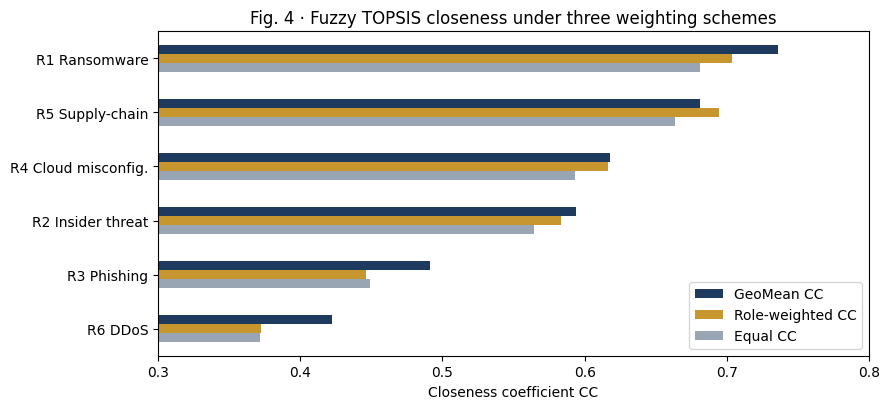

In [13]:
ax = topsis.drop(columns="Rank").plot.barh(figsize=(9, 4.2), color=[NAVY, GOLD, GREY])
ax.invert_yaxis(); ax.set_xlim(0.3, 0.8); ax.set_xlabel("Closeness coefficient CC")
ax.set_title("Fig. 4 · Fuzzy TOPSIS closeness under three weighting schemes"); plt.tight_layout(); plt.savefig("figures/fig4_topsis_cc.png", dpi=200)

## V-E · Monte Carlo robustness (10,000 runs, Dirichlet α = 40)

In [14]:
%%time
mc = {lab: E.mc_stats(R, w, runs=10_000, alpha=40, seed=42) for lab, w in [("GeoMean", w_gm), ("Role-weighted", w_rw), ("Equal", w_eq)]}
ve = pd.DataFrame({lab: s["p_top"] * 100 for lab, s in mc.items()}, index=L.ALTS).round(2)
ve.to_csv("results/VE_top1_share.csv"); ve.rename(columns=lambda c: c + " · P(rank 1) %")

CPU times: user 6.1 s, sys: 10.2 ms, total: 6.11 s
Wall time: 10.2 s


,GeoMean · P(rank 1) %,Role-weighted · P(rank 1) %,Equal · P(rank 1) %
R1 Ransomware,87.37,57.87,61.45
R2 Insider threat,0.00,0.00,0.00
R3 Phishing,0.00,0.00,0.00
R4 Cloud misconfig.,0.00,0.01,0.02
R5 Supply-chain,12.63,42.12,38.53
R6 DDoS,0.00,0.00,0.00


In [15]:
compare([["Top-1 stability, GeoMean",       f"{mc['GeoMean']['p_top'][0]*100:.1f}%",       "87.2%"],
         ["Top-1 stability, role-weighted", f"{mc['Role-weighted']['p_top'][0]*100:.1f}%", "57.2%"],
         ["Top-1 stability, equal weights", f"{mc['Equal']['p_top'][0]*100:.1f}%",         "62.8%"],
         ["Full-ranking stability, GeoMean",       f"{mc['GeoMean']['full_stab']*100:.1f}%",       "84.9%"],
         ["Full-ranking stability, role-weighted", f"{mc['Role-weighted']['full_stab']*100:.1f}%", "56.3%"]])

,Metric,This run,Paper
0,"Top-1 stability, GeoMean",87.4%,87.2%
1,"Top-1 stability, role-weighted",57.9%,57.2%
2,"Top-1 stability, equal weights",61.5%,62.8%
3,"Full-ranking stability, GeoMean",84.8%,84.9%
4,"Full-ranking stability, role-weighted",57.1%,56.3%


In [16]:
cc = mc["Role-weighted"]["cc"]
t14 = pd.DataFrame({"P(rank 1) %": mc["Role-weighted"]["p_top"] * 100, "Mean CC": cc.mean(0), "CC std": cc.std(0),
                    "P5": np.percentile(cc, 5, 0), "P95": np.percentile(cc, 95, 0)}, index=L.ALTS)
t14.to_csv("results/VE_table14.csv"); t14  # paper Table XIV

,P(rank 1) %,Mean CC,CC std,P5,P95
R1 Ransomware,57.87,0.704,0.043,0.628,0.768
R2 Insider threat,0.00,0.584,0.019,0.553,0.615
R3 Phishing,0.00,0.446,0.037,0.387,0.506
R4 Cloud misconfig.,0.01,0.617,0.026,0.575,0.660
R5 Supply-chain,42.12,0.694,0.030,0.642,0.741
R6 DDoS,0.00,0.372,0.032,0.321,0.424


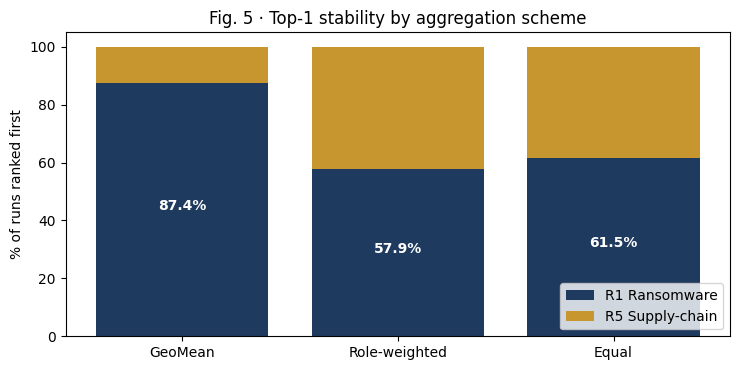

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 3.8)); labs = list(mc)
r1 = [mc[l]["p_top"][0] * 100 for l in labs]; r5 = [mc[l]["p_top"][4] * 100 for l in labs]
ax.bar(labs, r1, color=NAVY, label="R1 Ransomware"); ax.bar(labs, r5, bottom=r1, color=GOLD, label="R5 Supply-chain")
for i, v in enumerate(r1): ax.text(i, v / 2, f"{v:.1f}%", ha="center", color="white", fontweight="bold")
ax.set_ylabel("% of runs ranked first"); ax.set_title("Fig. 5 · Top-1 stability by aggregation scheme"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("figures/fig5_mc_top1.png", dpi=200)

## V-C · Baseline comparison (Table X)

In [18]:
W_before = np.array([L.buckley_weights(A)[0] for A in mats.values()])
W_after  = np.array([L.buckley_weights(A)[0] for A in refined.values()])
compare([["Expert matrices usable (CR ≤ 0.10)", f"{(va['CR before'] <= 0.1).sum()}/5 → 5/5", "3/5 → 5/5"],
         ["Targeted single-entry revisions", int(va["Iterations"].sum()), "4"],
         ["Mean pairwise expert distance (demo matrices)", f"{E.mean_pairwise_distance(W_before):.3f} → {E.mean_pairwise_distance(W_after):.3f}", "0.383 → 0.417"],
         ["Top-1 stability (MC)", f"{mc['GeoMean']['p_top'][0]*100:.1f}% → {mc['Role-weighted']['p_top'][0]*100:.1f}%", "87.2% → 57.2%"],
         ["Full-ranking stability (MC)", f"{mc['GeoMean']['full_stab']*100:.1f}% → {mc['Role-weighted']['full_stab']*100:.1f}%", "84.9% → 56.3%"]],
        cols=("Metric", "This run (baseline → LAF-MCDM)", "Paper"))

,Metric,This run (baseline → LAF-MCDM),Paper
0,Expert matrices usable (CR ≤ 0.10),3/5 → 5/5,3/5 → 5/5
1,Targeted single-entry revisions,2,4
2,Mean pairwise expert distance (demo matrices),0.394 → 0.394,0.383 → 0.417
3,Top-1 stability (MC),87.4% → 57.9%,87.2% → 57.2%
4,Full-ranking stability (MC),84.8% → 57.1%,84.9% → 56.3%


## V-G · Generalization stress test (200 synthetic panels, 1,000 matrices)

In [19]:
%%time
st = E.stress_test(R, Cred, panels=200, seed=7)
compare([["Matrices with CR > 0.1", f"{st['n_bad']} ({st['n_bad']/st['total']*100:.1f}%)", "171 (17.1%)"],
         ["Resolved to CR ≤ 0.1", f"{st['n_fixed']}/{st['n_bad']}", "171/171 (100%)"],
         ["Mean iterations per repaired matrix", f"{st['mean_iter']:.2f}", "1.11"],
         ["Dispersion change, mean / median", f"{st['disp'].mean():+.2f}% / {np.median(st['disp']):+.2f}%", "+0.75% / 0.0%"],
         ["Panels where dispersion increased", f"{(st['disp'] > 0).sum()}/200", "76/200"],
         ["Max GM–RW weight gap, mean / median", f"{st['gaps'].mean():.2f} / {np.median(st['gaps']):.2f} pp", "4.28 / 3.99 pp"],
         ["Gap [P5, P95]", f"[{np.percentile(st['gaps'],5):.2f}, {np.percentile(st['gaps'],95):.2f}]", "[1.73, 7.90]"]])

CPU times: user 559 ms, sys: 251 µs, total: 559 ms
Wall time: 572 ms


,Metric,This run,Paper
0,Matrices with CR > 0.1,173 (17.3%),171 (17.1%)
1,Resolved to CR ≤ 0.1,173/173,171/171 (100%)
2,Mean iterations per repaired matrix,1.13,1.11
3,"Dispersion change, mean / median",+1.20% / +0.00%,+0.75% / 0.0%
4,Panels where dispersion increased,77/200,76/200
5,"Max GM–RW weight gap, mean / median",4.16 / 3.81 pp,4.28 / 3.99 pp
6,"Gap [P5, P95]","[1.59, 7.75]","[1.73, 7.90]"


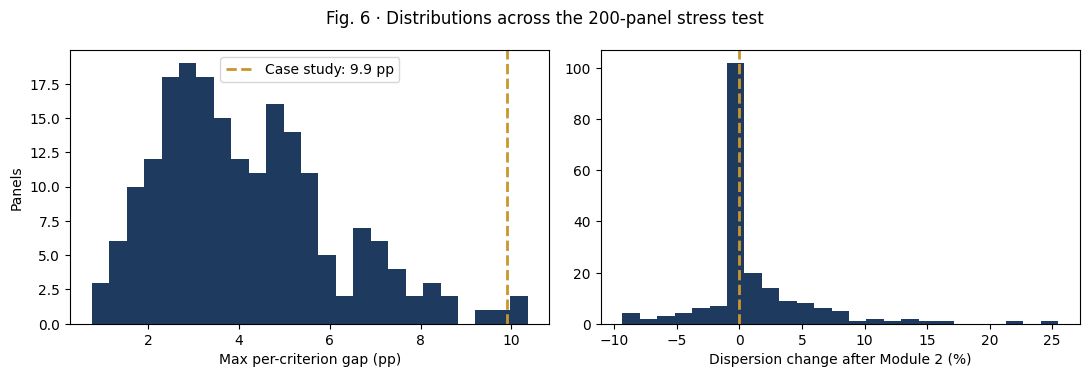

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].hist(st["gaps"], bins=25, color=NAVY); axs[0].axvline(9.9, color=GOLD, ls="--", lw=2, label="Case study: 9.9 pp")
axs[0].set_xlabel("Max per-criterion gap (pp)"); axs[0].set_ylabel("Panels"); axs[0].legend()
axs[1].hist(st["disp"], bins=25, color=NAVY); axs[1].axvline(0, color=GOLD, ls="--", lw=2)
axs[1].set_xlabel("Dispersion change after Module 2 (%)")
fig.suptitle("Fig. 6 · Distributions across the 200-panel stress test"); plt.tight_layout(); plt.savefig("figures/fig6_stress.png", dpi=200)

## V-H · Comparison of consistency-repair strategies (100 inconsistent matrices)

In [21]:
%%time
rc = E.repair_comparison(m=100, seed=11)
vh = pd.DataFrame(rc).T.rename(columns={"converged": "Converged /100", "mean_iter": "Mean iterations"})
vh["Paper mean iterations"] = [1.12, 1.12, 1.09, 1.09]; vh.to_csv("results/VH_repair_rules.csv"); vh

CPU times: user 12.9 s, sys: 38.7 ms, total: 13 s
Wall time: 13.2 s


,Converged /100,Mean iterations,Paper mean iterations
median,100.0,1.18,1.12
mean,100.0,1.17,1.12
geomean,100.0,1.16,1.09
direct,100.0,1.17,1.09


## V-I · Sensitivity to the role-credibility matrix (1,000 perturbations)

In [22]:
cs = E.credibility_sensitivity(W, Cred, R, n=1000, conc=30, seed=13)
compare([["Ransomware (R1) top-ranked", f"{cs['p_top'][0]*100:.1f}%", "83.6%"],
         ["Supply-chain (R5) top-ranked", f"{cs['p_top'][4]*100:.1f}%", "16.4%"],
         ["Mean max GM–RW gap", f"{cs['gaps'].mean():.2f} pp", "9.56 pp"],
         ["Gap [P5, P95]", f"[{np.percentile(cs['gaps'],5):.2f}, {np.percentile(cs['gaps'],95):.2f}]", "[7.22, 11.78]"]])

,Metric,This run,Paper
0,Ransomware (R1) top-ranked,82.8%,83.6%
1,Supply-chain (R5) top-ranked,17.2%,16.4%
2,Mean max GM–RW gap,9.62 pp,9.56 pp
3,"Gap [P5, P95]","[7.41, 11.73]","[7.22, 11.78]"


## V-J · Sensitivity to the Dirichlet concentration α (Table XV)

In [23]:
%%time
paper = {10: (73.0, 52.4), 20: (79.9, 55.2), 40: (87.6, 57.8), 80: (94.8, 60.4), 160: (98.9, 65.3), 320: (99.9, 73.0)}
vj = pd.DataFrame([(a, g, paper[a][0], r, paper[a][1]) for a, g, r in E.alpha_sweep(R, w_gm, w_rw, runs=5000, seed=17)],
                  columns=["α", "GeoMean %", "Paper GeoMean %", "Role-weighted %", "Paper role-weighted %"]).round(1)
vj.to_csv("results/VJ_alpha_sweep.csv", index=False); vj

CPU times: user 7.61 s, sys: 11.6 ms, total: 7.62 s
Wall time: 7.72 s


,α,GeoMean %,Paper GeoMean %,Role-weighted %,Paper role-weighted %
0,10,73.2,73.0,52.5,52.4
1,20,79.9,79.9,54.7,55.2
2,40,87.0,87.6,59.1,57.8
3,80,94.6,94.8,61.7,60.4
4,160,98.6,98.9,66.1,65.3
5,320,99.9,99.9,71.5,73.0


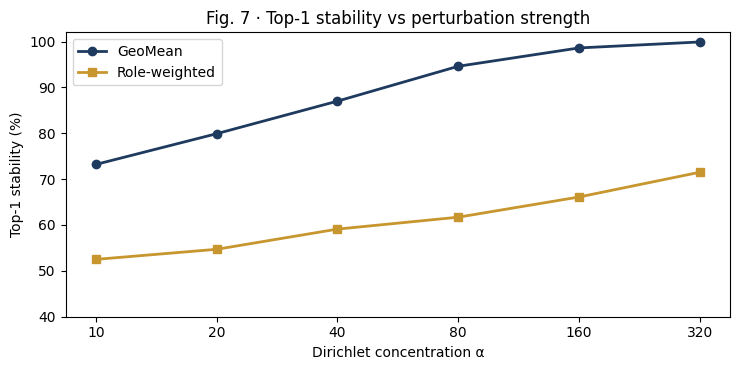

In [24]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(vj["α"], vj["GeoMean %"], "o-", color=NAVY, lw=2, label="GeoMean")
ax.plot(vj["α"], vj["Role-weighted %"], "s-", color=GOLD, lw=2, label="Role-weighted")
ax.set_xscale("log", base=2); ax.set_xticks(vj["α"]); ax.set_xticklabels(vj["α"])
ax.set_xlabel("Dirichlet concentration α"); ax.set_ylabel("Top-1 stability (%)"); ax.set_ylim(40, 102); ax.legend()
ax.set_title("Fig. 7 · Top-1 stability vs perturbation strength"); plt.tight_layout(); plt.savefig("figures/fig7_alpha.png", dpi=200)

## Download all results and figures

In [25]:
import shutil; shutil.make_archive("LAF_MCDM_results", "zip", ".", "results"); shutil.make_archive("LAF_MCDM_figures", "zip", ".", "figures")
print(sorted(os.listdir("results"))); print(sorted(os.listdir("figures")))
try:
    from google.colab import files; files.download("LAF_MCDM_results.zip"); files.download("LAF_MCDM_figures.zip")
except ImportError:
    print("Not on Colab: zips saved next to the notebook.")

['VA_consistency.csv', 'VD_topsis.csv', 'VD_weights.csv', 'VE_table14.csv', 'VE_top1_share.csv', 'VH_repair_rules.csv', 'VJ_alpha_sweep.csv']
['fig4_topsis_cc.png', 'fig5_mc_top1.png', 'fig6_stress.png', 'fig7_alpha.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>